## **一、S5-01｜图文怎样互读，图像怎样保留行列**

S4-02 的 Plain DiT 中，图像 token 可以读取文本，冻结文本塔输出的 token 作为条件输入。现在把文字和图像放进同一次注意力计算。图像可以读取文字，文字也可以读取图像，具体开放哪条边由 mask 决定。与此同时，图像被展平成 token 后仍需知道哪个 patch 在右边或下方。这是 2D RoPE 要解决的问题。[S3 的 Cross-Attention](S3_文本条件CFG与可信评测.ipynb) · [S4-02 的 Plain DiT](S4_02_LatentFlow与PlainDiT训练闭环.ipynb)

| 顺序 | 这一步能验证什么 |
| --- | --- |
| 手算可见矩阵 | 哪些 query 能读取哪些 key，屏蔽后如何重新归一化 |
| 逐轴推导 2D RoPE | 位置怎样进入打分，什么时候共同平移保持图像打分 |
| 对照实现 | 共享或分开投影怎样接到一次联合 softmax，SDPA 是否复现显式公式 |
| 短训 | 当输入的唯一空间线索是 RoPE 时，同参数小模型能否学会相对位置检索 |
| 亲手实现 | 只写最小旋转和联合 attention，各有一格独立验收 |

使用项目已有的 Python 内核和 PyTorch、Matplotlib，从上到下执行。数值对照用 CPU FP64，小型训练用 CPU FP32 和固定种子。代码仅使用内存里的小张量，图表保存在 Notebook 输出里。若要另存自己的合成数据或结果，可放到独立的 `artifacts/learning/s5_01/`，保留种子和规则版本。

### **1. 先看 3 个文本位置与 4 个图像位置**

取文本 $T_0,T_1,\mathrm{pad}$ 和按行排列的 $I_{00},I_{01},I_{10},I_{11}$。先把所有 query 和 key 向量设为零，合法打分相同，softmax 就是在可见 key 上取均匀平均。每个 value 是一个标量，按上述顺序取 $10,20,999,1,2,3,4$。其中 999 是故意放进去的 padding 干扰。

> **手算。** 双向策略下，有效文本和图像 query 都看见六个合法 key，输出 $(10+20+1+2+3+4)/6=40/6$。若文本块内部双向且只读文本，$T_0$ 读到 $10,20$，输出 $15$。图像仍能看见图文两路，输出仍为 $40/6$。下方图里每行是 query，每列是 key，蓝色表示可见。padding 行与列都应留白。

Bidirectional        T0=6.666667, I00=6.666667


Block-causal example T0=15.000000, I00=6.666667


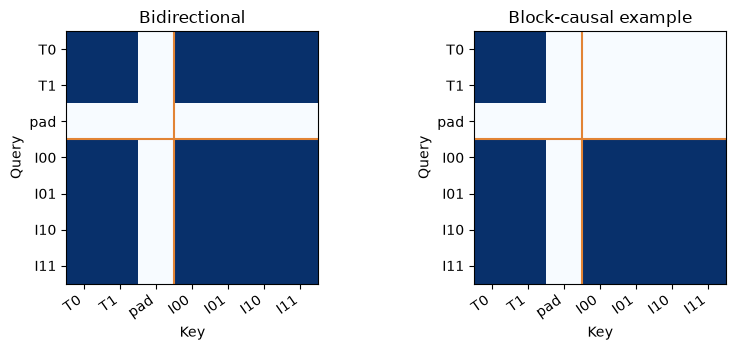

Python 3.12.14 | PyTorch 2.14.1 | CPU


In [1]:
import math
import sys
from collections.abc import Callable
from time import perf_counter

import matplotlib.pyplot as plt
import torch
from torch import Tensor, nn
from torch.nn import functional as F

torch.set_num_threads(min(4, torch.get_num_threads()))
dtype = torch.float64
labels = ("T0", "T1", "pad", "I00", "I01", "I10", "I11")
valid = torch.tensor([[True, True, False, True, True, True, True]])
prefix = torch.ones(7, 7, dtype=torch.bool)
prefix[:3, 3:] = False
visible = valid[:, :, None] & valid[:, None, :]
policies = {"Bidirectional": visible[0], "Block-causal example": visible[0] & prefix}
values = torch.tensor([10, 20, 999, 1, 2, 3, 4], dtype=dtype).reshape(1, 1, 7, 1)
zeros = torch.zeros(1, 1, 7, 4, dtype=dtype)

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6))
for ax, (name, mask) in zip(axes, policies.items(), strict=True):
    active = (0, 3)  # 只取两个有效 query，对应 T0、I00。
    rows = mask[list(active)]
    scores = zeros[:, :, list(active)]
    out = F.scaled_dot_product_attention(scores, zeros, values, attn_mask=rows, dropout_p=0)
    print(f"{name:20} T0={out[0, 0, 0, 0]:.6f}, I00={out[0, 0, 1, 0]:.6f}")
    expected = [15, 40 / 6] if name.startswith("Block") else [40 / 6, 40 / 6]
    torch.testing.assert_close(out.flatten(), torch.tensor(expected, dtype=dtype))
    ax.imshow(mask.numpy(), cmap="Blues", vmin=0, vmax=1)
    ax.set(xticks=range(7), yticks=range(7), title=name, xlabel="Key", ylabel="Query")
    ax.set_xticklabels(labels, rotation=35, ha="right")
    ax.set_yticklabels(labels)
    ax.axvline(2.5, color="#e28435")
    ax.axhline(2.5, color="#e28435")
fig.tight_layout()
plt.show()
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | CPU")

## **二、Joint Attention｜连接方式和参数共享是两件事**

### **1. 从 Q、K、V 追踪谁读谁**

设某个头的 query 是 $q_i\in\mathbb R^{d_h}$，key 是 $k_j\in\mathbb R^{d_h}$，value 是 $v_j\in\mathbb R^{d_v}$。$q_i$ 描述位置 $i$ 想读什么，$k_j$ 用来匹配，$v_j$ 是读到的内容。先算匹配分数 $s_{ij}=q_i^\top k_j/\sqrt{d_h}$，再沿 key 轴归一化。若各维度的乘积近似独立、零均值且方差约为 1，未缩放和的方差约为 $d_h$。除以 $\sqrt{d_h}$ 后，初始打分量级更稳定。令 $\mathcal A_i$ 是第 $i$ 行合法 key 的集合，输出为

$$a_{ij}=\frac{\exp(s_{ij})}{\sum_{\ell\in\mathcal A_i}\exp(s_{i\ell})}\quad(j\in\mathcal A_i),\qquad o_i=\sum_{j\in\mathcal A_i}a_{ij}v_j$$

| 本课对比 | Q 来自哪里 | K/V 来自哪里 | 更新了哪些 token |
| --- | --- | --- | --- |
| 图像 Self-Attention | 图像 | 图像 | 图像 |
| Plain DiT 的图读文 Cross-Attention | 图像 | 文本 | 图像 |
| 双向 Joint Attention | 文本和图像 | 文本和图像 | 文本和图像 |

合并顺序为 $[T;I]$，打分矩阵的四个块是 $Q_TK_T^\top$、$Q_TK_I^\top$、$Q_IK_T^\top$、$Q_IK_I^\top$。行属 query 模态，列属 key 模态。右上块开放时文字才能直接读图。联合计算让可见的图、文 key 共享 **同一个 softmax 分母**。如果对两个 key 池各算一次 softmax 再相加，每池都已各自归一化为 1，权重意义会变。在第一节的均匀例子里，文本两键均值为 $15$，图像四键均值为 $2.5$。联合平均是 $(2\cdot15+4\cdot2.5)/6=40/6$，与两次输出直接相加的 $17.5$ 不同。

公式要求 $\mathcal A_i$ 非空，集合之外的键权重为零。缩放量来自方差相加：若 $d_h$ 个乘积独立、方差为 1，则 $\operatorname{Var}(\sum_{k=1}^{d_h} q_{ik}k_{jk})=d_h$，除以 $\sqrt{d_h}$ 会把方差缩到 1。这是用来解释初始打分量级的近似。空行的处理见第四章。 [Attention Is All You Need 第 3.2.1 节](https://arxiv.org/html/1706.03762v7#S3.SS2.SSS1)

### **2. 两种实现都能共享一次 softmax**

1. **拼接后共享投影。** 两种 token 已投到相同模型宽度。先按 token 轴拼接，再用同一套 $W_Q,W_K,W_V$ 得到 Q/K/V。逐 token 的线性层对拼接可交换，等价于用同一套参数先分别投影，再拼 Q/K/V。
2. **分模态投影。** 文本与图像各自使用 $W_Q^{(T/I)},W_K^{(T/I)},W_V^{(T/I)}$。它们可以对两种输入分布学不同的映射。投影后头数与每头 Q/K 宽度要一致，两路 V 的每头宽度也须相同。沿 token 轴拼 Q、K、V，用一次联合 attention。结束后按原来的 $n_t,n_i$ 拆回两条输出流。

这两个选择改变参数共享，但信息流还由 mask 决定。MMDiT 是分模态权重、图文双向交互的一个公开例子。SD3 的 MMDiT 把模态独立的参数用到了 Transformer Block，包含两路投影、调制与前馈。本节只把焦点放在 Q/K/V 接入联合算子的位置，S6-01 再组装完整双流块。 [SD3 论文第 4 节与图 2(b)](https://arxiv.org/html/2403.03206v1#S4)

以单个样本、单个头为单位，S4-02 的图像 self 加图读文 cross 分别产生 $n_i^2$ 与 $n_i n_t$ 个分数。双向联合的密集矩阵有 $(n_i+n_t)^2$ 个分数。取 $n_i=256,n_t=77$，两者分别为 $85{,}248$ 和 $110{,}889$。这个计数没有把冻结文本编码器、投影、MLP 和内核实现算进去。普通密集 mask 即使屏蔽部分边，也未必跳过对应算力。比较训练成本要另外测设备、batch、精度和内核。

## **三、2D RoPE｜把相对行列位移写进点积**

### **1. 从一对通道的旋转开始**

同一个方形 patch 放到不同坐标，内容可以一样。如果打分只看内容，就不能直接区别哪个在右边。Rotary Position Embedding（旋转位置编码，RoPE）在打分前按位置旋转 Q 和 K 的成对通道。它保持每个二维向量的长度，改变跨位置两向量的相位差。本课给 V 保留原值，注意力读出的内容仍来自原始 V。[RoFormer 原论文](https://arxiv.org/abs/2104.09864v5)

对通道对 $u=(a,b)^\top$，令旋转矩阵为

$$R(\theta)=\begin{pmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{pmatrix}$$

于是新坐标是 $(a\cos\theta-b\sin\theta,\ a\sin\theta+b\cos\theta)$。若第 $j$ 对通道的频率为 $\omega_j$，对位于 $p$ 的 query 和位于 $s$ 的 key 分别用 $\theta_q=p\omega_j$ 和 $\theta_k=s\omega_j$。利用 $R(\theta)^\top=R(-\theta)$ 和二维旋转可相加，得到

$$[R(p\omega_j)q]^\top[R(s\omega_j)k]=q^\top R(-p\omega_j)R(s\omega_j)k=q^\top R((s-p)\omega_j)k$$

这条等式的符号与代码约定对应。我们在 Q、K 两端都用正角度，所以相对位移写成 **key 坐标减 query 坐标**。同时平移两端坐标，$s-p$ 不变。若只转 Q、不转 K，便不会得到这条相对位置等式。

### **2. 在行轴和列轴上分别旋转**

图像坐标取 $(y,x)$，$y$ 是行，$x$ 是列。网格从左上角 $(0,0)$ 开始，按行优先展平。

| patch 序号 | $(y,x)$ | 向右或向下一个 patch |
| --- | --- | --- |
| 0 | $(0,0)$ | 向右到 1，向下到 2 |
| 1 | $(0,1)$ | 向下到 3 |
| 2 | $(1,0)$ | 向右到 3 |
| 3 | $(1,1)$ | 位于右下 |

对每个头，前一半通道用于 $y$，后一半用于 $x$。每半又按相邻两通道成对，因此本课约定 $d_h$ 是 4 的正整数倍。令每轴的通道对数为 $m=d_h/4$，以基数 $10^4$ 设 $\omega_j=(10^4)^{-j/m}$，其中 $j=0,\ldots,m-1$。同一轴的第 $j$ 对分别转 $y\omega_j$ 或 $x\omega_j$。例如 $d_h=8$ 时，两个轴都用频率 $1,0.01$。拼回的张量形状仍为 `[b,a,n,d_h]`，$a$ 表示头数。其他代码可能用前后半配对、不同的频率布局或混合坐标方向。复用已有权重前要核对定义。[RoPE-ViT 对轴向和混合 2D RoPE 的比较](https://arxiv.org/abs/2403.13298v2)

> **手算两个打分。** 取 $q=k=(1,0,1,0)$，$q$ 在 $(0,0)$，$k$ 在 $(0,1)$。行通道保持 $(1,0)$，列通道旋转为 $(\cos1,\sin1)$，所以未缩放的点积为 $1+\cos1\approx1.54030$。若改为 $q=(1,0,0,0),k=(0,1,0,0)$，把 key 下移到 $(1,0)$，点积是 $-\sin1\approx-0.84147$。只右移到 $(0,1)$ 时，key 的行通道未旋转，点积仍为 0。这两种输入可检查轴顺序与相对位移的符号。

下面的张量实现把最后一维重排为 `[...,2,m,2]`，三个新增轴分别表示行列、频率与每对两个分量。角度张量的 head 轴是 1，用同一组频率广播到各头。三角函数至少用 FP32 计算，本课对严格数值验证保留 FP64。

把同一头的行、列旋转写成块对角矩阵 $R(y,x)=R_y(y)\oplus R_x(x)$，其中每个轴还包含多对频率。两块彼此独立，于是 $R(y_q,x_q)^\top R(y_k,x_k)=R_y(y_k-y_q)\oplus R_x(x_k-x_q)$。这就是从一维相对相位得到二维相对位移的步骤。RoPE-ViT 还讨论了让同一对通道同时感受两个轴的混合设计。轴向相位每对只含一项，混合相位可以写成 $y\omega_{y,j}+x\omega_{x,j}$，频率轴与通道划分需要随模型定义读取。 [RoPE-ViT 第 3.2 节](https://arxiv.org/html/2403.13298v2#S3.SS2)

In [2]:
def grid_coords(
    height: int,
    width: int,
) -> Tensor:
    """给出行优先 patch 的 [n,2] 整数坐标，最后一维依次为 y、x。"""
    y, x = torch.meshgrid(torch.arange(height), torch.arange(width), indexing="ij")
    return torch.stack((y, x), dim=-1).reshape(-1, 2)


def rotate_2d(
    features: Tensor,
    coords: Tensor,
) -> Tensor:
    """轴向 RoPE。features 为 [b,a,n,d]；coords 为 [n,2] 或 [b,n,2]。"""
    if features.ndim != 4 or not features.is_floating_point():
        raise ValueError("expected floating [b,a,n,d] features")
    batch, _, tokens, width = features.shape
    if width == 0 or width % 4:
        raise ValueError("head width must be a positive multiple of 4")
    if coords.shape == (tokens, 2):
        coords = coords.unsqueeze(0)
    elif coords.shape != (batch, tokens, 2):
        raise ValueError("expected [n,2] or [b,n,2] coordinates")
    pairs = width // 4
    work_dtype = torch.float64 if features.dtype == torch.float64 else torch.float32
    index = torch.arange(pairs, device=features.device, dtype=work_dtype)
    freq = torch.exp(-math.log(10_000.0) * index / pairs)
    angles = coords.to(device=features.device, dtype=work_dtype)[:, None, :, :, None] * freq
    real, imag = features.to(work_dtype).reshape(*features.shape[:-1], 2, pairs, 2).unbind(-1)
    cos, sin = angles.cos(), angles.sin()
    rotated = torch.stack((real * cos - imag * sin, real * sin + imag * cos), dim=-1)
    return rotated.reshape_as(features).to(features.dtype)


print("row-major 2x2 patch positions:", grid_coords(2, 2).tolist())

row-major 2x2 patch positions: [[0, 0], [0, 1], [1, 0], [1, 1]]


### **3. 图像位置和文本位置分别处理**

本课的策略是 **只旋转图像 Q/K**。S4-02 的 CLIP token 本身已经过带位置编码的文本塔。在联合层里，文本维持自己的内容表示，不被赋予图像行列坐标。其他实现可以用文本的一维位置、保留独立模态轴或共享某些位置规则。训练和推理须采用同一套约定。

共同平移后保持不变的是固定内容下的 **图像对图像打分**。例如文本 query $(1,0,0,0)$ 不旋转，图像 key 初值同它。当图像 key 从 $(0,0)$ 移到 $(1,0)$，跨模态点积从 $1$ 变成 $\cos 1$。因此联合 softmax 和整个模型的输出一般不享有相同的平移性质。绝对位置特征、图像边界、mask 和 patch 内容的变化也能改变整体结果。

用标准库标量三角计算核对一个 8 维向量，再检查向量范数、共享与逐样本坐标、共同平移和 Q/K 数值梯度。这里核对的是算子，输入向量没有语义信息。

In [3]:
origin = torch.tensor([[0, 0]])
row_step = torch.tensor([[1, 0]])
col_step = torch.tensor([[0, 1]])
axis_q = torch.tensor([1.0, 0.0, 0.0, 0.0], dtype=dtype).reshape(1, 1, 1, 4)
axis_k = torch.tensor([0.0, 1.0, 0.0, 0.0], dtype=dtype).reshape_as(axis_q)
dot_row = (rotate_2d(axis_q, origin) * rotate_2d(axis_k, row_step)).sum()
dot_col = (rotate_2d(axis_q, origin) * rotate_2d(axis_k, col_step)).sum()
torch.testing.assert_close(dot_row, torch.tensor(-math.sin(1), dtype=dtype))
torch.testing.assert_close(dot_col, torch.zeros((), dtype=dtype))

rng = torch.Generator().manual_seed(50101)
features = torch.randn(2, 2, 4, 8, dtype=dtype, generator=rng)
keys = torch.randn(features.shape, dtype=dtype, generator=rng)
coords = grid_coords(2, 2)
q = rotate_2d(features, coords)
k = rotate_2d(keys, coords)
torch.testing.assert_close(q.norm(dim=-1), features.norm(dim=-1), rtol=0, atol=2e-15)
shifted = coords + torch.tensor([7, 11])
batched = rotate_2d(features, torch.stack((coords, shifted)))
torch.testing.assert_close(batched[0], q[0])
torch.testing.assert_close(batched[1:], rotate_2d(features[1:], shifted))
same_scores = rotate_2d(features, shifted) @ rotate_2d(keys, shifted).transpose(-1, -2)
shift_error = (same_scores - q @ k.transpose(-1, -2)).abs().max()
assert shift_error < 1e-13

# 用标准库标量矩阵单独复算一条 8 维向量（两个频率、两个轴）。
sample = features[0, 0, 3].tolist()
expected = []
for axis in range(2):
    for j, frequency in enumerate((1.0, 0.01)):
        theta = coords[3, axis].item() * frequency
        a0, a1 = sample[axis * 4 + j * 2 : axis * 4 + j * 2 + 2]
        expected.extend(
            (
                math.cos(theta) * a0 - math.sin(theta) * a1,
                math.sin(theta) * a0 + math.cos(theta) * a1,
            )
        )
torch.testing.assert_close(q[0, 0, 3], torch.tensor(expected, dtype=dtype))

# 文本未旋转时，图像单侧平移可改变跨模态打分。
text_query = axis_q
cross_before = (text_query * rotate_2d(axis_q, origin)).sum().item()
cross_after = (text_query * rotate_2d(axis_q, row_step)).sum().item()
assert math.isclose(cross_before, 1.0) and math.isclose(cross_after, math.cos(1))

tiny_q = features[:1, :1, :2].clone().requires_grad_()
tiny_k = keys[:1, :1, :2].clone().requires_grad_()


def rotary_scores(
    queries: Tensor,
    key_vectors: Tensor,
) -> Tensor:
    """为数值梯度检查返回旋转后的 Q/K 打分。"""
    return rotate_2d(queries, coords[:2]) @ rotate_2d(key_vectors, coords[:2]).transpose(-1, -2)


assert torch.autograd.gradcheck(rotary_scores, (tiny_q, tiny_k))
print(f"row dot={dot_row:.8f}; column dot={dot_col:.8f}")
print(f"image-image common-shift max error={shift_error:.2e}")
print(f"mixed dot after image-only shift {cross_before:.6f} -> {cross_after:.6f}")
print("RoPE scalar oracle, norm, shared/batched coordinates and Q/K gradcheck passed")

row dot=-0.84147098; column dot=0.00000000
image-image common-shift max error=1.78e-15
mixed dot after image-only shift 1.000000 -> 0.540302
RoPE scalar oracle, norm, shared/batched coordinates and Q/K gradcheck passed


## **四、联合 mask｜先确定合法边，再沿 key 归一化**

### **1. 逻辑矩阵的三层约束**

对同一批 token，分别维护文本有效位和图像有效位，拼成 `valid [b,n_t+n_i]`。本课统一使用布尔 True 表示有效。构造 `allowed [b,1,N,N]`，第一个 $N$ 是 query 轴，第二个是 key 轴。头轴为 1，允许对多个头广播。逻辑上

$$M_{bij}=\operatorname{valid}_{bi}\land\operatorname{valid}_{bj}\land\operatorname{policy}_{ij}$$

| 约束 | 实际含义 |
| --- | --- |
| key 有效 | 无效文本 padding 或图像 padding 不进入任何合法行的分母 |
| query 有效 | 本课约定无效 query 的返回值为零；后续注意力仍要用键掩码挡住这些位置 |
| policy 可见 | 双向允许图文互读。开头图里的 block-causal 示例屏蔽文本 query 到图像 key 的边 |

这个教学矩阵把文本和图像各视为一个内部双向的块，文本只读自身，图像能读两块。Qwen-Image-2.1 对文本按 **逐 token 因果** 处理，并给每张图像独立的双向块。其合法键须满足 $j\le i$ 或与 query 同属一个图像块。回到开头等分数的例子，Qwen 的 $T_0$ 只读到 $10$，教学图里的 $T_0$ 读到的是两项均值 $15$。只有一张图像且排在最后时，$I_{00}$ 在两种策略里都能读六个有效键。Qwen 的编辑前缀还有图文交错的情形，详见 S5-02。 [Qwen 官方架构](https://github.com/QwenLM/Qwen-Image-2.1#architecture)

### **2. SDPA 约定和无合法 key 的行**

PyTorch 的 `scaled_dot_product_attention`（SDPA）直接接受投影后的 Q/K/V。它的布尔 `attn_mask` 为 True 时表示 **可参与注意力**。迁移到 `nn.MultiheadAttention` 的 `key_padding_mask` 时要反过来，该接口 True 表示忽略。浮点 mask 则是对 logits 的加性偏置，浮点 0/1 与布尔 True/False 含义不同。[PyTorch SDPA 文档](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html) · [PyTorch MultiheadAttention 文档](https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html)

若某行完全没有合法 key，普通的「先填负无穷、再 softmax」没有可归一的概率分布。不同内核和版本可能有自己的行为。本课先算 `has_key`，仅为全空行在内核输入临时开放一个占位 key。随后用 `where` 把这些行的输出置零，合法行不变，空行的损失梯度也不会流经占位读取。该实现假定输入有限、打分不溢出且总序列非空。真实 block 若有残差、MLP 或有偏置的输出层，仍须在需要的边界保持无效位置约束。单次 attention 置零只保证这个算子自己的输出。

`key_padding_mask` 约束的是键，padding query 的输出约定要另外处理。调用函数式 SDPA 时，评估应显式给 `dropout_p=0.0`，因为外层模块的 `eval()` 不会替这个函数改参数。 [PyTorch SDPA 文档](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html) · [PyTorch MultiheadAttention 文档](https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html)

## **五、用同一组 Q/K/V 对照显式矩阵和 SDPA**

### **1. 形状、旋转位置与分流边界**

| 张量 | 教学用形状 | 要核对的含义 |
| --- | --- | --- |
| Text / Image | `[2,3,8]` / `[2,4,8]` | 两个样本，3 个文本位置与 4 个图像位置 |
| Text Q/K/V | `[2,2,3,4]` | 头数 2，每头宽度 4 |
| Image Q/K/V | `[2,2,4,4]` | 对其中 Q/K 用网格坐标旋转 |
| 拼接后 Q/K/V | `[2,2,7,4]` | 先文后图，拼 token 轴 |
| 可见矩阵 | `[2,1,7,7]` | [batch, head broadcast, query, key] |
| 分流输出 | `[2,2,3,4]` / `[2,2,4,4]` | 仍由原长度拆分，下一步才按需投影 |

先比较「先拼接再用共享线性层」与「两路各用同一个线性层，再拼接结果」，用同一组权重看它们的数值是否相等。随后对文本与图像分别投影、只对图像 Q/K 旋转，再进入同一个联合算子。模型内常见的输出投影、残差与 FFN 留到 S5-02、S6-01 组装。

In [4]:
QKV = tuple[Tensor, Tensor, Tensor]


def project_qkv(
    tokens: Tensor,
    linear: nn.Linear,
    heads: int,
) -> QKV:
    """[b,n,d_model] 投影为三份 [b,a,n,d_h]。"""
    b, n, _ = tokens.shape
    q, k, v = linear(tokens).reshape(b, n, 3, heads, -1).permute(2, 0, 3, 1, 4).unbind()
    return q, k, v


def joint_reference(
    text_qkv: QKV,
    image_qkv: QKV,
    text_valid: Tensor,
    image_valid: Tensor,
    policy: Tensor | None = None,
) -> tuple[Tensor, Tensor]:
    """在同一 key 轴归一化，按拼接长度拆回文本和图像；无合法 key 的行置零。"""
    q, k, v = (torch.cat((t, x), dim=2) for t, x in zip(text_qkv, image_qkv, strict=True))
    valid = torch.cat((text_valid, image_valid), dim=1)
    allowed = valid[:, None, :, None] & valid[:, None, None, :]
    if policy is not None:
        allowed = allowed & policy
    has_key = allowed.any(dim=-1, keepdim=True)
    # 空行给内核一个临时 key，再把整行输出清零。逻辑可见矩阵没有改变。
    first_key = torch.arange(k.shape[2], device=k.device) == 0
    safe = allowed | (~has_key & first_key)
    out = F.scaled_dot_product_attention(q, k, v, attn_mask=safe, dropout_p=0.0)
    out = torch.where(has_key, out, 0.0)
    return out.split((text_valid.shape[1], image_valid.shape[1]), dim=2)


with torch.random.fork_rng(devices=[]):
    torch.manual_seed(50102)
    shared = nn.Linear(8, 24, dtype=dtype)
    text_only = nn.Linear(8, 24, dtype=dtype)
    image_only = nn.Linear(8, 24, dtype=dtype)
text = torch.randn(2, 3, 8, dtype=dtype, generator=rng)
image = torch.randn(2, 4, 8, dtype=dtype, generator=rng)
whole = project_qkv(torch.cat((text, image), dim=1), shared, 2)
shared_t = project_qkv(text, shared, 2)
shared_i = project_qkv(image, shared, 2)
for all_tokens, part_t, part_i in zip(whole, shared_t, shared_i, strict=True):
    torch.testing.assert_close(all_tokens, torch.cat((part_t, part_i), dim=2))

t_valid = torch.tensor([[True, True, False], [False, False, False]])
i_valid = torch.tensor([[True, True, True, False], [False, False, False, False]])
split_t = project_qkv(text, text_only, 2)
iq, ik, iv = project_qkv(image, image_only, 2)
split_i = (rotate_2d(iq, coords), rotate_2d(ik, coords), iv)
out_t, out_i = joint_reference(split_t, split_i, t_valid, i_valid)
assert out_t.shape == (2, 2, 3, 4) and out_i.shape == (2, 2, 4, 4)
print("shared QKV after concat equals same projection per modality")
print(f"separate QKV, same joint operation -> T{tuple(out_t.shape)}, I{tuple(out_i.shape)}")

shared QKV after concat equals same projection per modality
separate QKV, same joint operation -> T(2, 2, 3, 4), I(2, 2, 4, 4)


### **2. 四项独立检查**

- **等价性。** 单头、单行地枚举可见 key，显式算点积、softmax、value 加权，再对照 SDPA 的所有行。对照覆盖双向与块策略。
- **padding 隔离。** 改写无效文本和图像位置的 Q/K/V，合法行结果应保持不变。完全无合法 key 的样本保持有限。
- **方向性。** 只改变图像 value。双向时文本输出应改变，禁止文本读图时该输出应保持。
- **反向。** 单独从一个无合法 key 的 query 回传，检查所有输入梯度为零。然后对包含合法行的输出回传，核对其梯度有限且可达，整条全 padding 的样本梯度仍为零。

In [5]:
def row_oracle(
    query: Tensor,
    keys: Tensor,
    values: Tensor,
    permitted: Tensor,
) -> Tensor:
    """单头单 query 的显式 softmax，仅遍历可见 key。"""
    indices = permitted.nonzero().flatten().tolist()
    if not indices:
        return torch.zeros_like(values[0])
    logits = torch.stack([query.dot(keys[j]) / math.sqrt(query.numel()) for j in indices])
    return logits.softmax(0) @ values[indices]


jq, jk, jv = (torch.cat((t, x), dim=2) for t, x in zip(split_t, split_i, strict=True))
j_valid = torch.cat((t_valid, i_valid), dim=1)
for policy in (torch.ones_like(prefix), prefix):
    allowed = j_valid[:, :, None] & j_valid[:, None, :] & policy
    explicit = torch.stack(
        [
            torch.stack(
                [
                    torch.stack(
                        [
                            row_oracle(jq[b, h, n], jk[b, h], jv[b, h], allowed[b, n])
                            for n in range(7)
                        ]
                    )
                    for h in range(2)
                ]
            )
            for b in range(2)
        ]
    )
    actual = torch.cat(joint_reference(split_t, split_i, t_valid, i_valid, policy), dim=2)
    torch.testing.assert_close(actual, explicit, rtol=1e-12, atol=1e-12)
    assert torch.isfinite(actual).all()

edited_t = tuple(torch.where(t_valid[:, None, :, None], x, 100.0) for x in split_t)
edited_i = tuple(torch.where(i_valid[:, None, :, None], x, -100.0) for x in split_i)
check_t, check_i = joint_reference(edited_t, edited_i, t_valid, i_valid)
torch.testing.assert_close(out_t, check_t)
torch.testing.assert_close(out_i, check_i)

# 只改图像 value；双向文本输出变化，block-causal 文本输出不变。
shifted_i = (split_i[0], split_i[1], split_i[2] + 1)
both_new, _ = joint_reference(split_t, shifted_i, t_valid, i_valid)
blocked, _ = joint_reference(split_t, split_i, t_valid, i_valid, prefix)
blocked_new, _ = joint_reference(split_t, shifted_i, t_valid, i_valid, prefix)
assert (both_new - out_t).abs().max() > 0.01
torch.testing.assert_close(blocked, blocked_new)

leaf_t = tuple(x.detach().clone().requires_grad_() for x in split_t)
leaf_i = tuple(x.detach().clone().requires_grad_() for x in split_i)
# 样本 1 全 padding，样本 0 的有效 T0 也因 policy 单独失去所有可读 key。
no_first_row = torch.ones_like(prefix)
no_first_row[0, :] = False
yt, yi = joint_reference(leaf_t, leaf_i, t_valid, i_valid, no_first_row)
torch.testing.assert_close(yt[0, :, 0], torch.zeros_like(yt[0, :, 0]))
zero_grads = torch.autograd.grad(yt[0, :, 0].sum(), (*leaf_t, *leaf_i), retain_graph=True)
assert all(torch.count_nonzero(g).item() == 0 for g in zero_grads)
grads = torch.autograd.grad(yt.square().sum() + yi.square().sum(), (*leaf_t, *leaf_i))
assert all(torch.isfinite(g).all() and torch.count_nonzero(g[1]) == 0 for g in grads)
assert all(torch.count_nonzero(g[0]).item() > 0 for g in grads)
print("explicit row oracle agrees with SDPA for both masks")
print("padding perturbation, directionality, all-masked rows and gradients passed")

explicit row oracle agrees with SDPA for both masks
padding perturbation, directionality, all-masked rows and gradients passed


## **六、CPU 小训练｜没有位置信息时能读到右边吗**

### **1. 把任务限制到可解释的空间检索**

每例有一个 $3\times3$ 网格。九个位置各取独立随机值 $v_j\in\{-1,+1\}$。从左上 $2\times2$ 区域随机选 query 的坐标，再随机选「向右一格」或「向下一格」，以保证目标在网格内。**每例独立打乱 key 的顺序**，把位置和值一起重排。标签是目标位置存的标量，目标索引只用于构造监督与评分。

模型只学习两个方向各自的 4 维 query、一个所有位置共享的 4 维 key，一共 12 个参数。Value 原样进入加权平均，从未用于 Q/K 打分。没有序号 embedding、绝对位置表或目标标记。方向通过两条可学习 query 的选择进入模型，能区分两种检索命令。无位置组完全忽略坐标，轴向 RoPE 组只在旋转 Q/K 时读取 query 与 key 坐标。这个任务把联合注意力的信息流检查和空间先验的训练检查分开了。

### **2. 两条解析基准先验算任务**

无位置时，每行所有 key 都来自同一个向量，因此九个 logits 总相等，输出 $\widehat y=\frac19\sum_j v_j$。设目标索引为 $i$。独立随机符号满足 $\mathbb E[v_j]=0$、$\mathbb E[v_j^2]=1$，所以误差平方取期望时交叉项消失，只保留系数平方。

$$\mathbb E[(\widehat y-v_i)^2]=\left(\tfrac19-1\right)^2+8\left(\tfrac19\right)^2=\tfrac89$$

更一般地，给定布局与方向，权重 $w_j$ 与这一例独立生成的随机值无关。把 $\widehat y-v_i$ 展成 $(w_i-1)v_i+\sum_{j\ne i}w_jv_j$，取条件期望时交叉项仍为零，因此误差是 $(1-w_i)^2+\sum_{j\ne i}w_j^2$。即使目标在每例都是最大权重，只要还有概率分给其他位置，这个误差就可以为正。

$8/9$ 是 **本实验九键均匀读取基线** 的期望。能额外识别 query 所在 key 或使用其他位置特征的模型有不同基线。样本均值接近 $8/9$ 即合理，无需精确相等。

还可以写出一个能定位的 RoPE 解。每轴只有一对通道，频率为 1。令每轴 key 为 $(1,0)$，目标偏移 $\tau$ 对应的 query 为 $(\cos\tau,\sin\tau)$。相对位移为 $\delta$ 时，点积就是 $\cos(\delta-\tau)$。两个轴的分数相加，在目标相对坐标 $\delta_y=\tau_y,\delta_x=\tau_x$ 取最大。这个网格里候选位置与目标的每轴差在 $[-2,2]$，没有另一个同峰位置。用此构造核验目标索引与打分轴。扩大网格时余弦有周期，目标与相距较远的位置可能打分接近，这个单频解的表现不能外推。

In [6]:
def retrieval_batch(
    count: int,
    generator: torch.Generator,
) -> tuple[Tensor, Tensor, Tensor, Tensor, Tensor]:
    """随机打乱 3×3 patch；独立抽值，目标来自 query 右方或下方一格。"""
    perm = torch.rand(count, 9, generator=generator).argsort(dim=-1)
    positions = grid_coords(3, 3)[perm]
    anchor = torch.randint(2, (count, 2), generator=generator)
    direction = torch.randint(2, (count,), generator=generator)
    offset = torch.stack((direction, 1 - direction), dim=1)
    hit = (positions == (anchor + offset)[:, None, :]).all(dim=-1)
    assert (hit.sum(dim=1) == 1).all()
    target_index = hit.long().argmax(dim=1, keepdim=True)
    value = torch.randint(2, (count, 9), generator=generator).float() * 2 - 1
    return positions, anchor, direction, value, target_index


class LookupProbe(nn.Module):
    """两条方向 query 和一个共享 key 向量。两组均为 12 个可训练标量。"""

    def __init__(self, rotary: bool, seed: int) -> None:
        super().__init__()
        rng = torch.Generator().manual_seed(seed)
        self.query = nn.Parameter(torch.randn(2, 4, generator=rng) * 0.5)
        self.key = nn.Parameter(torch.randn(4, generator=rng) * 0.5)
        self.rotary = rotary

    def forward(
        self,
        positions: Tensor,
        anchor: Tensor,
        direction: Tensor,
        values: Tensor,
    ) -> tuple[Tensor, Tensor]:
        q = self.query[direction][:, None, None, :]
        k = self.key.expand(len(values), 1, values.shape[1], 4)
        if self.rotary:
            q = rotate_2d(q, anchor[:, None, :])
            k = rotate_2d(k, positions)
        scores = (q @ k.transpose(-2, -1)).squeeze(1).squeeze(1) / 2.0
        weights = scores.softmax(dim=-1)
        return (weights * values).sum(dim=1, keepdim=True), weights


holdout = retrieval_batch(2048, torch.Generator().manual_seed(50199))
vp, va, vd, vv, vi = holdout
vy = vv.gather(1, vi)
assert set(vd.tolist()) == {0, 1}

# 解析对照有正确的 argmax。训练不使用这些参数，目标索引只构造标量标签和评分。
oracle = LookupProbe(True, 50100)
with torch.no_grad():
    oracle.key.copy_(torch.tensor([1.0, 0.0, 1.0, 0.0]))
    oracle.query.copy_(
        torch.tensor([[1.0, 0.0, math.cos(1), math.sin(1)], [math.cos(1), math.sin(1), 1.0, 0.0]])
    )
    _, oracle_weights = oracle(vp, va, vd, vv)
assert torch.equal(oracle_weights.argmax(dim=1, keepdim=True), vi)
print("oracle top1 checked on holdout; directions right/down:", vd.bincount().tolist())

oracle top1 checked on holdout; directions right/down: [1004, 1044]


### **3. 预先固定对照，观察留出损失**

| 项目 | 设置 |
| --- | --- |
| 训练组 | 相同 12 参数，同种子初始化及相同批次，区别仅在 Q/K 是否旋转 |
| 优化 | Adam，学习率 0.05，batch 64，固定 240 步，不加权重衰减 |
| 重复 | 3 对训练种子，配对共享各自的随机训练序列 |
| 留出 | 独立种子一次生成 2,048 例，仍是 $3\times3$，值和顺序独立于训练抽样 |
| 读数 | 留出 MSE、目标 key 的平均权重、权重 argmax 命中、向右与向下各自误差 |

训练损失只看读出的标量与目标标量的 MSE。目标位置的注意力权重和 top-1 只用于留出诊断。两组按固定步数报告，留出指标没有用于挑 checkpoint。训练第一个更新核查 RoPE 组有非零梯度，无位置组梯度接近零，后一现象与「所有打分共同变化仍是均匀分布」一致。总共 6 次小训练，使用本地 CPU，数据和参数均在内存中。

seed | no-pos MSE | RoPE MSE | target weight | RoPE top1 | right MSE | down MSE
50111 | 0.87599 | 0.00081 | 0.97688 | 1.00000 | 0.00059 | 0.00102
50112 | 0.87599 | 0.00088 | 0.97573 | 1.00000 | 0.00064 | 0.00110
50113 | 0.87599 | 0.00087 | 0.97551 | 1.00000 | 0.00069 | 0.00104
same holdout, common shift (7,11): max weight delta 2.38e-07
CPU runtime 0.50s; 3 paired seeds, 240 updates per model


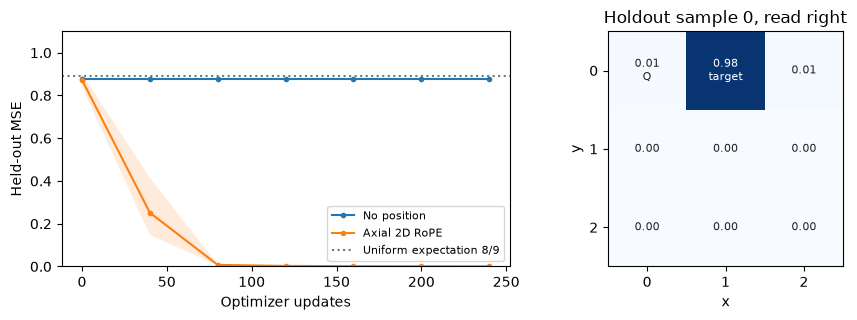

In [7]:
update_points = (0, 40, 80, 120, 160, 200, 240)
seeds = (50111, 50112, 50113)
curves = {"No position": [], "Axial 2D RoPE": []}
records = {}
stamp = perf_counter()
for seed in seeds:
    plain = LookupProbe(False, seed)
    rope = LookupProbe(True, seed)
    for p, r in zip(plain.parameters(), rope.parameters(), strict=True):
        torch.testing.assert_close(p, r, rtol=0, atol=0)
    pair = (plain, rope)
    optimizers = [torch.optim.Adam(m.parameters(), lr=0.05) for m in pair]
    train_rng = torch.Generator().manual_seed(seed + 1000)
    histories = [[], []]
    for step in range(update_points[-1] + 1):
        if step in update_points:
            with torch.no_grad():
                for model, history in zip(pair, histories, strict=True):
                    pred, _ = model(vp, va, vd, vv)
                    history.append((pred - vy).square().mean().item())
        if step == update_points[-1]:
            break
        pos, anchor, direction, value, target_index = retrieval_batch(64, train_rng)
        target = value.gather(1, target_index)
        for model, optimizer in zip(pair, optimizers, strict=True):
            optimizer.zero_grad(set_to_none=True)
            pred, _ = model(pos, anchor, direction, value)
            loss = (pred - target).square().mean()
            assert torch.isfinite(loss)
            loss.backward()
            grad_total = sum(p.grad.abs().sum().item() for p in model.parameters())
            assert math.isfinite(grad_total)
            if step == 0:
                assert grad_total > 1e-5 if model.rotary else grad_total < 1e-5
            optimizer.step()
    curves["No position"].append(histories[0])
    curves["Axial 2D RoPE"].append(histories[1])
    with torch.no_grad():
        plain_pred, plain_weights = plain(vp, va, vd, vv)
        rope_pred, rope_weights = rope(vp, va, vd, vv)
        torch.testing.assert_close(plain_pred, vv.mean(dim=1, keepdim=True))
        torch.testing.assert_close(plain_weights, torch.full_like(plain_weights, 1 / 9))
        mse_by_direction = [
            (rope_pred[vd == i] - vy[vd == i]).square().mean().item() for i in range(2)
        ]
        prob = rope_weights.gather(1, vi).mean().item()
        top1 = (rope_weights.argmax(dim=1, keepdim=True) == vi).float().mean().item()
    records[seed] = (histories[0][-1], histories[1][-1], prob, top1, *mse_by_direction)
    if seed == seeds[0]:
        first_rope = rope

print("seed | no-pos MSE | RoPE MSE | target weight | RoPE top1 | right MSE | down MSE")
for seed, row in records.items():
    print(f"{seed} | " + " | ".join(f"{x:.5f}" for x in row))
with torch.no_grad():
    _, first_weights = first_rope(vp, va, vd, vv)
    _, translated = first_rope(vp + torch.tensor([7, 11]), va + torch.tensor([7, 11]), vd, vv)
    translation_error = (first_weights - translated).abs().max().item()
    torch.testing.assert_close(first_weights, translated, rtol=0, atol=3e-5)
print(f"same holdout, common shift (7,11): max weight delta {translation_error:.2e}")
print(f"CPU runtime {perf_counter() - stamp:.2f}s; 3 paired seeds, 240 updates per model")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), gridspec_kw={"width_ratios": [1.45, 1]})
for name, history in curves.items():
    trial = torch.tensor(history)
    axes[0].plot(update_points, trial.mean(0), marker="o", markersize=3, label=name)
    axes[0].fill_between(update_points, trial.min(0).values, trial.max(0).values, alpha=0.15)
axes[0].axhline(8 / 9, color="#767676", linestyle=":", label="Uniform expectation 8/9")
axes[0].set(xlabel="Optimizer updates", ylabel="Held-out MSE", ylim=(0, 1.1))
axes[0].legend(fontsize=8)
maps = torch.zeros(3, 3)
maps[vp[0, :, 0], vp[0, :, 1]] = first_weights[0]
direction_name = "right" if vd[0].item() == 0 else "down"
axes[1].imshow(maps, cmap="Blues", vmin=0, vmax=1)
axes[1].set(
    xticks=range(3),
    yticks=range(3),
    xlabel="x",
    ylabel="y",
    title=f"Holdout sample 0, read {direction_name}",
)
for y in range(3):
    for x in range(3):
        suffix = "\nQ" if [y, x] == va[0].tolist() else ""
        if [y, x] == vp[0, vi[0, 0]].tolist():
            suffix = "\ntarget"
        w = maps[y, x].item()
        axes[1].text(
            x,
            y,
            f"{w:.2f}{suffix}",
            ha="center",
            va="center",
            color="white" if w > 0.6 else "#202020",
            fontsize=8,
        )
fig.tight_layout()
plt.show()

### **4. 结果能说明什么**

- 三个种子的无位置组留出 MSE 均为 $0.87599$，与同一批留出样本上的均匀读出相等，也接近理论期望 $8/9$。
- RoPE 组的末步留出 MSE 在 $0.00081$ 到 $0.00088$ 之间，两种方向的误差均低于本课基线。三个模型的权重 argmax 都命中 2,048 个目标，平均目标权重约 $0.976$。仍有少量权重落在其他位置，所以回归误差没有到零。
- 保持整批留出样本的值和全可见策略，只对所有 query/key 坐标同时平移 $(7,11)$，FP32 权重最大变化约为 $2.4\times10^{-7}$。这复验相对位置公式，测试网格大小仍是 $3\times3$。

这个结果回答「当内容不能提供位置，旋转能否给共享 key 的检索器提供位置区分」。它不比较 RoPE 与其他位置编码，也没有训练图文生成模型。分辨率变化、跨模态条件、纹理质量和实际 DiT 的训练成本各需另外控制。右图标注一例留出权重，Q 是查询坐标，target 是应读取的邻格。左图阴影是三次运行的最小值到最大值，不是置信区间。

## **七、只练两个核心函数**

### **1. 练习输入与输出**

先关闭上面的参考格。把 TODO 留在本课练习格，填完再运行验收格。教学演示使用独立参考函数，个人函数未填会明确显示待完成。

| 函数 | 输入 | 输出约定 |
| --- | --- | --- |
| `apply_2d_rope(q,k,coords)` | 等形浮点 Q/K `[b,a,n,d_h]`，共用 `coords [n,2]`，顺序 $(y,x)$ | 同形两份旋转结果，保持 dtype 和梯度。$d_h$ 为 4 的正整数倍，非法头宽抛 `ValueError` |
| `joint_attention(text_qkv,image_qkv,text_valid,image_valid)` | 两路已投影 Q/K/V、两路 bool 有效位 | 先文后图双向可见，用一个 softmax，再按原长度拆回。无合法 key 的行输出 0。V 的宽度可与 Q/K 不同 |

### **2. 验收为什么能查出常见错误**

RoPE 用坐标 $(1,2)$ 分别旋转两个基向量，检查成对通道、行列轴、符号以及非法头宽。回传输出之和时，每对输入梯度应为 $(\cos\theta+\sin\theta,\cos\theta-\sin\theta)$，用这个闭式值核对 Q/K。

联合注意力先用开头的 $40/6$ 检验 padding 与分流，再加入一条非均匀行。令 $d_h=4$，让首行 query 的首坐标为 2，首个合法 key 的首坐标为 $\log2$。缩放后只有这一项 logit 为 $\log2$。它的指数权重由 1 变 2，输出变成 $(40+10)/(6+1)=50/7$。这样能抓住始终取平均、漏缩放或把归一化轴写反的实现。

In [8]:
def apply_2d_rope(
    q: Tensor,
    k: Tensor,
    coords: Tensor,
) -> tuple[Tensor, Tensor]:
    """个人练习：同一批 [n,2] 坐标分别旋转等形 Q 与 K。"""
    raise NotImplementedError("apply_2d_rope")


def joint_attention(
    text_qkv: QKV,
    image_qkv: QKV,
    text_valid: Tensor,
    image_valid: Tensor,
) -> tuple[Tensor, Tensor]:
    """个人练习：双向联合 attention，按原长度分流，空行输出为零。"""
    raise NotImplementedError("joint_attention")

In [9]:
def check_rope_exercise() -> None:
    """独立核对两个轴的手算值、梯度、shape 和非法头宽。"""
    left = torch.tensor([1.0, 0.0, 1.0, 0.0], dtype=dtype).reshape(1, 1, 1, 4)
    right = torch.tensor([0.0, 1.0, 0.0, 1.0], dtype=dtype).reshape_as(left)
    left.requires_grad_()
    right.requires_grad_()
    point = torch.tensor([[1, 2]])
    a, b = apply_2d_rope(left, right, point)
    expect_a = torch.tensor([math.cos(1), math.sin(1), math.cos(2), math.sin(2)], dtype=dtype)
    expect_b = torch.tensor([-math.sin(1), math.cos(1), -math.sin(2), math.cos(2)], dtype=dtype)
    assert a.shape == b.shape == left.shape
    torch.testing.assert_close(a.flatten(), expect_a)
    torch.testing.assert_close(b.flatten(), expect_b)
    (a.sum() + b.sum()).backward()
    expected_grad = torch.tensor(
        [
            math.cos(1) + math.sin(1),
            math.cos(1) - math.sin(1),
            math.cos(2) + math.sin(2),
            math.cos(2) - math.sin(2),
        ],
        dtype=dtype,
    )
    torch.testing.assert_close(left.grad.flatten(), expected_grad)
    torch.testing.assert_close(right.grad.flatten(), expected_grad)
    try:
        apply_2d_rope(left[..., :3], right[..., :3], point)
    except ValueError:
        return
    raise AssertionError("d not divisible by four must raise ValueError")


def check_joint_exercise() -> None:
    """手算 3+4 token 的平均，核对屏蔽、拆分、梯度和全空行。"""
    qk = torch.zeros(2, 1, 7, 4, dtype=dtype)
    vals = values.expand(2, -1, -1, -1).clone().requires_grad_()
    t_mask = torch.tensor([[True, True, False], [False, False, False]])
    i_mask = torch.tensor([[True] * 4, [False] * 4])
    left = (qk[:, :, :3], qk[:, :, :3], vals[:, :, :3])
    right = (qk[:, :, 3:], qk[:, :, 3:], vals[:, :, 3:])
    t, i = joint_attention(left, right, t_mask, i_mask)
    assert t.shape == (2, 1, 3, 1) and i.shape == (2, 1, 4, 1)
    actual = torch.cat((t, i), dim=2).reshape(2, 7)
    expected = torch.zeros_like(actual)
    expected[0, [0, 1, 3, 4, 5, 6]] = 40 / 6
    torch.testing.assert_close(actual, expected)
    actual.sum().backward()
    weights = torch.cat((t_mask, i_mask), dim=1).to(dtype)
    torch.testing.assert_close(vals.grad.reshape(2, 7), weights)

    query, keys = qk.clone(), qk.clone()
    query[0, 0, 0, 0] = 2
    keys[0, 0, 0, 0] = math.log(2)
    skewed_t, _ = joint_attention(
        (query[:, :, :3], keys[:, :, :3], left[2]),
        (query[:, :, 3:], keys[:, :, 3:], right[2]),
        t_mask,
        i_mask,
    )
    torch.testing.assert_close(skewed_t[0, 0, 0, 0], torch.tensor(50 / 7, dtype=dtype))


checks: list[tuple[str, Callable[[], None]]] = [
    ("apply_2d_rope", check_rope_exercise),
    ("joint_attention", check_joint_exercise),
]
for name, check in checks:
    try:
        check()
    except NotImplementedError:
        print(f"{name}: 待完成")
    else:
        print(f"{name}: 通过")

apply_2d_rope: 待完成
joint_attention: 待完成


## **八、自测与 S5-02 的接口**

<details>
<summary>1. 分模态投影以后做联合注意力，为什么仍有双向信息流？</summary>

投影只改变每种 token 怎样生成 Q/K/V。拼好后，文字 query 仍能和图像 key 打分，图像 query 也能和文字 key 打分。是否真的读取取决于对应的 mask 边。对所有合法 key 仍只有一个 softmax 分母。

</details>

<details>
<summary>2. 为什么 2D RoPE 不直接用展平后的序号？</summary>

当网格宽度为 2，序号 1 与 2 相差 1，但它们的坐标分别为 $(0,1)$ 与 $(1,0)$，对应下移且左移。展开序号只保留一条轴的差。轴向旋转分别编码行差与列差。

</details>

<details>
<summary>3. 为什么要同时检查 key padding 和 query padding？</summary>

屏蔽 key 保证其他 token 不会读到 padding。处理 query 行保证 padding 本身不会产生有内容的输出。前者影响 softmax 的分母，后者定义无效行的返回值。做完残差和 FFN 后若仍要保持零，还要遵守整个 block 的约定。

</details>

<details>
<summary>4. 为什么翻转图文互读方向后，不能只比较张量形状？</summary>

双向与块策略可以有完全相同的形状。显式枚举合法键可以直接核对公式。固定 Q/K 后单独改变图像 V，则能验证实现中的文字输出是否依赖图像内容。

</details>

本课验收分开记录。解析与数值对照覆盖相对点积、频率、mask、分流与梯度。短训覆盖同参数下的位置检索。个人两项实现由你填写后单独验收。S5-02 会在这套 `[T;I]` 约定上组装共享残差块，最后只从图像区间恢复速度 patch。 [S5-02 单流主干与 Qwen 架构](S5_02_SingleStreamDiT架构与实现.ipynb) · [v2 学习目录](../MiniGen2学习目录.md)